# Petition publications and median signatures over time

## Load in libraries and data

In [1]:
# Libraries
import pickle
import statistics
import matplotlib.pyplot as plt
import re
import pandas as pd
from collections import Counter
import numpy as np
from collections import OrderedDict
import math
from datetime import date
from datetime import datetime, timedelta
from scipy.stats import median_test
import statistics
import matplotlib.dates as mdates

In [2]:
# Read in data - replace with final deidentified pkl files

with open('../data/aus/clean/aus_deidentified_min_fields.pkl', 'rb') as f:
    aus = pickle.load(f, encoding="utf-8")

with open('../data/canada/clean/can_deidentified_min_fields.pkl', 'rb') as f:
    can = pickle.load(f, encoding="utf-8")
    
with open('../data/uk/clean/uk_deidentified_min_fields.pkl', 'rb') as f:
    uk = pickle.load(f, encoding="utf-8")
    
with open('../data/germany/clean/ger_sigs_dates.pkl', 'rb') as f:
    ger = pickle.load(f, encoding="utf-8")

## Prepare, reorder, and reformat data

In [3]:
df = pd.DataFrame(ger).T.reset_index().rename(columns = {'index': 'id'}).sort_values(by = ['date', 'id'], ascending = [True, True])
df = df[['id', 'date', 'signatures']]

#df[df['date_string'] == '2010-09-22'] #.tolist()

In [4]:
def create_chron_data(epets): 
    df = pd.DataFrame(epets).T.reset_index().rename(columns = {'index': 'id'}).sort_values(by = ['date', 'id'], ascending = [True, True])
    df = df[['id', 'date', 'signatures']]
    
    dates_ordered = df['date'].tolist()
    signatures_ordered = df['signatures'].tolist()
    
    return df, dates_ordered, signatures_ordered

In [5]:
df_aus, dates_chron_aus, sigs_chron_aus = create_chron_data(aus)

In [6]:
df_can, dates_chron_can, sigs_chron_can  = create_chron_data(can)

In [7]:
df_uk, dates_chron_uk, sigs_chron_uk  = create_chron_data(uk)

In [8]:
df_ger, dates_chron_ger, sigs_chron_ger  = create_chron_data(ger)

In [9]:
aus_elections =[datetime(2022, 5, 21, 0, 0, 0), 
 datetime(2019, 5, 18, 0, 0, 0)] # datetime(2016, 7, 2, 0, 0, 0) # datetime(2025, 5, 3, 0, 0, 0), 

can_elections = [datetime(2025, 4, 28, 0, 0, 0), 
                 datetime(2021, 9, 20, 0, 0, 0), 
                 datetime(2019, 10, 21, 0, 0, 0)] # datetime(2015, 10, 19, 0, 0, 0)

uk_elections = [datetime(2024, 7, 4, 0, 0, 0),
datetime(2019, 12, 12, 0, 0, 0),
datetime(2017, 6, 8, 0, 0, 0),
datetime(2015, 5, 7, 0, 0, 0)] #datetime(2010, 5, 6, 0, 0, 0)


ger_elections = [datetime(2021, 9, 26, 0, 0, 0),
datetime(2017, 9, 24, 0, 0, 0),
datetime(2013, 9, 22, 0, 0, 0),
datetime(2009, 9, 27, 0, 0, 0)]
# datetime(2025, 2, 23, 0, 0, 0),
# 23 February 2025 - 26 September 2021 - 24 September 2017 - 22 September 2013 - 27 September 2009

## Figure 1

In [10]:
def sliding_window_medians(data, window_size = 100, step = 10, median_type = 'median_low'): #, sort_list = False
    # Create the windows
    windows = [data[i:i + window_size] for i in range(0, len(data) - window_size + 1, step)]
    if len(data) % step != 0: # final window will be the last 100 values with a smaller step value between it and the penultimate window
        windows.append(data[-window_size:])
        
    # Get the median window value for each window
    import statistics
     # returns lowest of 2 middle points
    if median_type == 'median_low':
        window_median_list = [statistics.median_low(w) for w in windows] # returns median
    else:
        window_median_list = [statistics.median(w) for w in windows]
        
    print(len(window_median_list))
        
    return window_median_list, windows

def create_df(window_medians, median_dates): 
    import pandas as pd
    # Convert list of lists to DataFrame
    df = pd.DataFrame({'Medians': window_medians, 'Dates': median_dates})
    
    return df

In [11]:
def petition_rate_per_window(windows_list):
    windows_rates = []
    for w in windows_list:
        # get the number of days between the start and end of the window:
        days_diff = max(w) - min(w)
        days_diff = days_diff.days + 1 # adding start date - if 2 days, diff = 1, but there are 2 dates
        r = len(w)/days_diff*365
        windows_rates.append(r)  
    return windows_rates

187
187
93
93
2599
2599
324
324


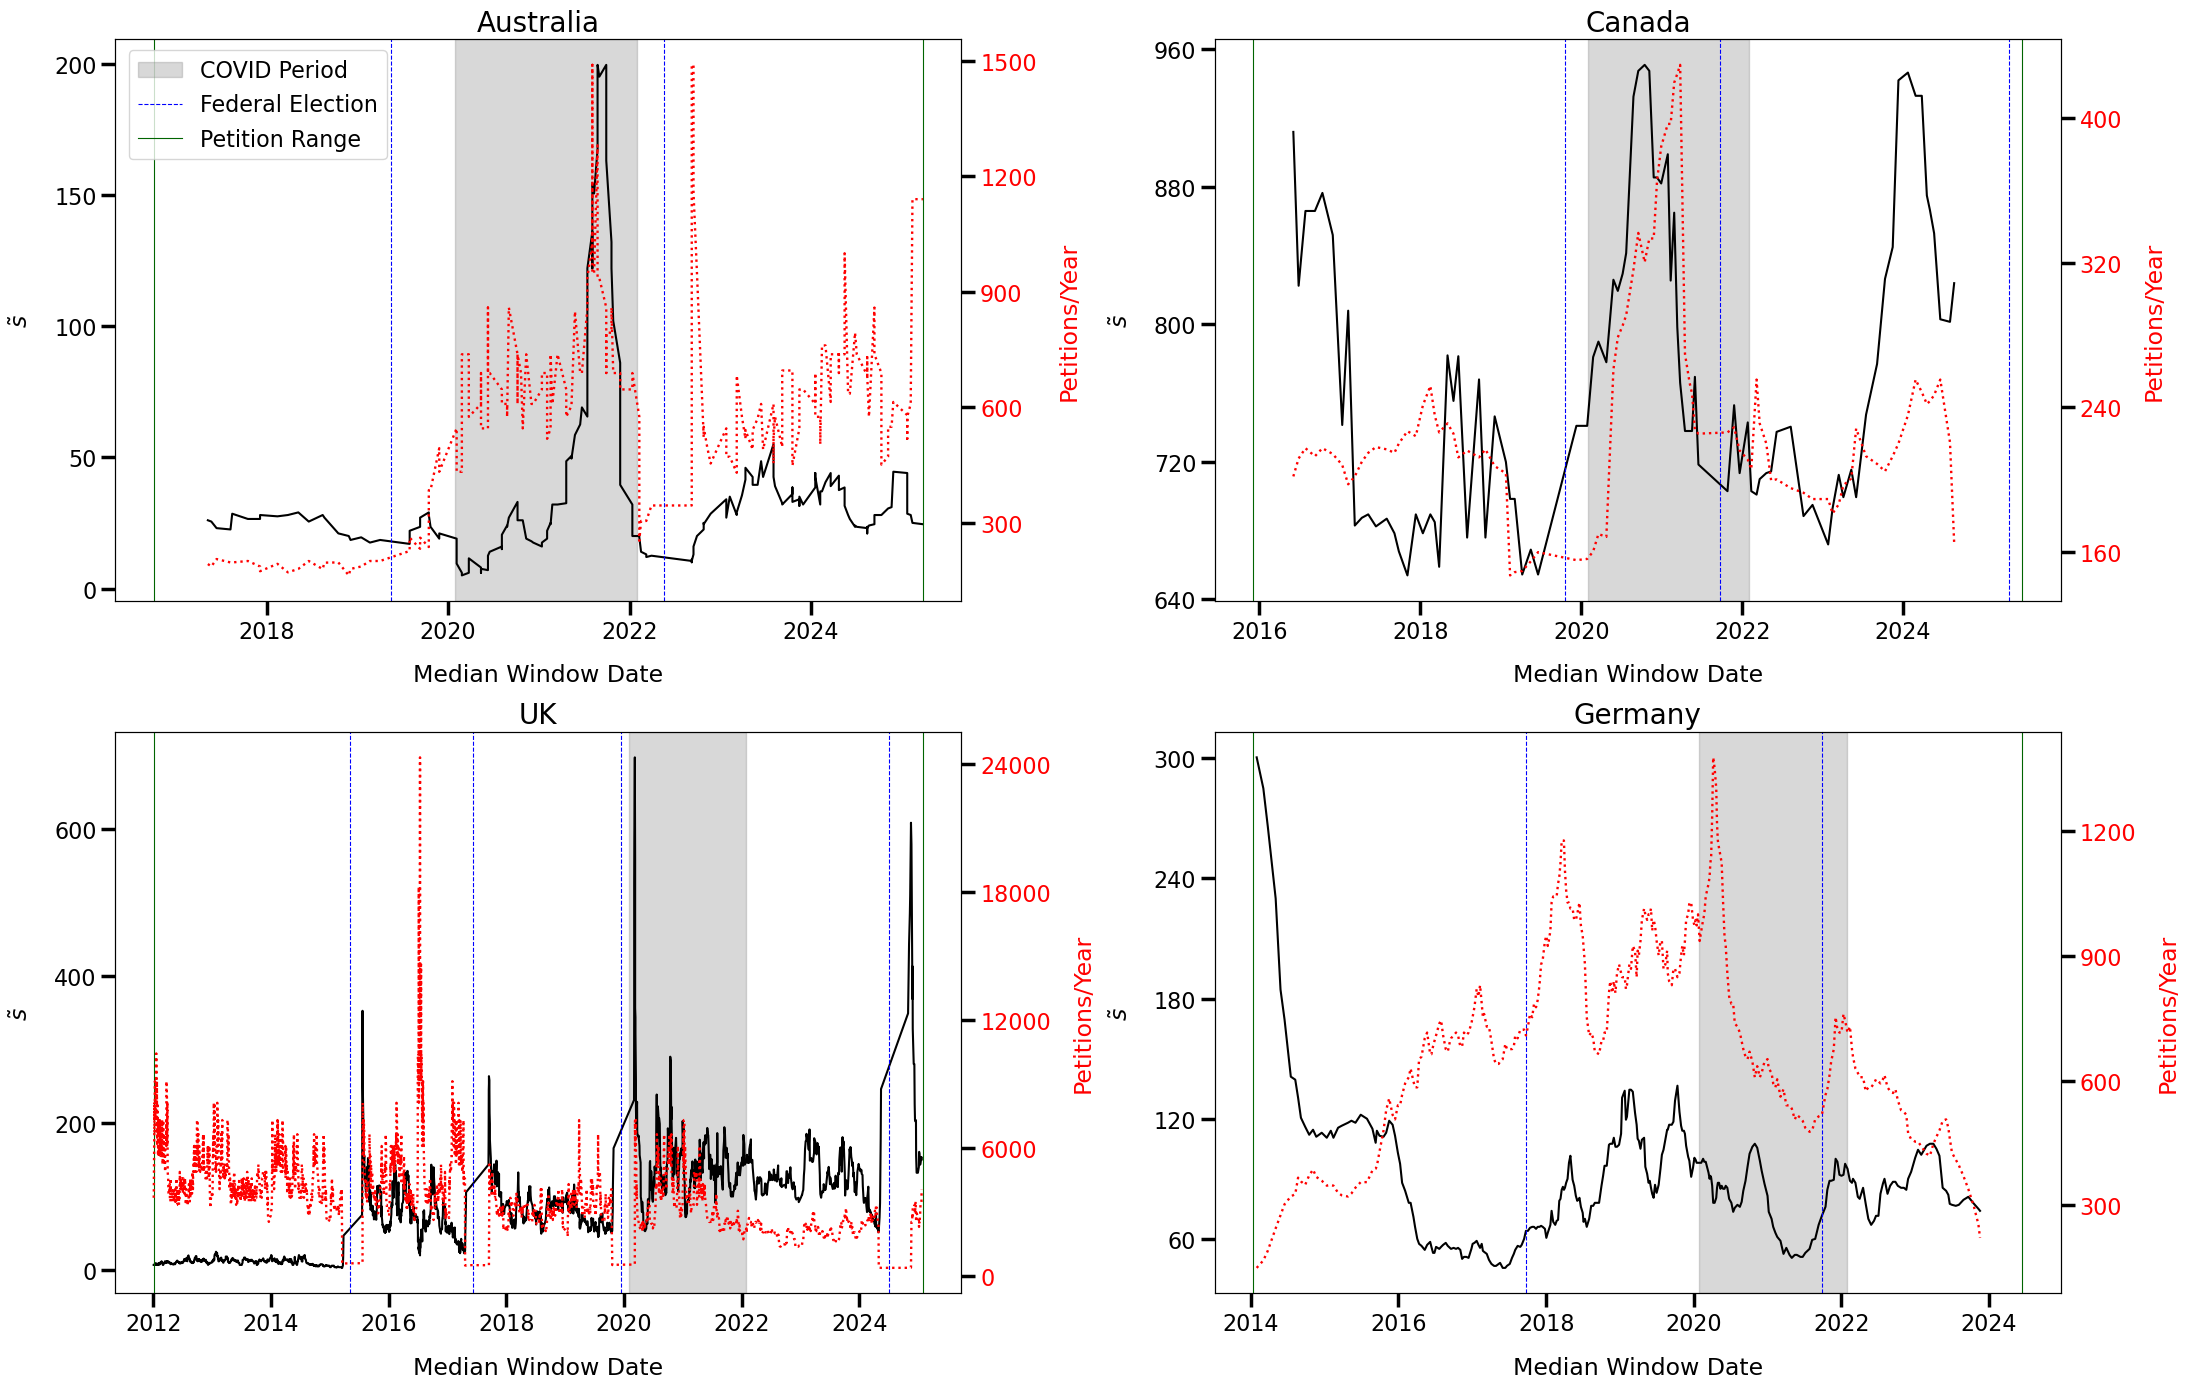

In [12]:
aus_elections =[datetime(2022, 5, 21, 0, 0, 0), 
                datetime(2019, 5, 18, 0, 0, 0)]

can_elections = [datetime(2025, 4, 28, 0, 0, 0), 
                 datetime(2021, 9, 20, 0, 0, 0), 
                 datetime(2019, 10, 21, 0, 0, 0)]

uk_elections = [datetime(2024, 7, 4, 0, 0, 0),
datetime(2019, 12, 12, 0, 0, 0),
datetime(2017, 6, 8, 0, 0, 0),
datetime(2015, 5, 7, 0, 0, 0)]


ger_elections = [datetime(2021, 9, 26, 0, 0, 0),
datetime(2017, 9, 24, 0, 0, 0)] 

from matplotlib.ticker import MaxNLocator

def plot_median_over_time(epet_dates, sig_list_chron, country, window_size = 100, lag = 10, ax=None, in_dates=None, plot_date_filt = None):
    median_window_dates, dates_windows_list = sliding_window_medians(epet_dates, window_size, lag, median_type = 'median_low')
    median_window_sigs, sigs_windows_list = sliding_window_medians(sig_list_chron, window_size, lag, median_type = 'median')
    sig_medians_df = create_df(median_window_sigs, median_window_dates)
    rate_of_pets = petition_rate_per_window(dates_windows_list)
    covid_start = datetime(2020, 1, 30, 0, 0, 0)
    covid_end = datetime(2022, 1, 30, 0, 0, 0)

    # Filtering German data to only plot from 01/01/2015 onwards
    if plot_date_filt != None:
        epet_dates = [x for x in epet_dates if x >= plot_date_filt]
        # 1. Find the first row number (integer index) where score >= 90 in df1
        row_num = np.where(sig_medians_df['Dates'] >= plot_date_filt)[0][0]
        sig_medians_df = sig_medians_df[sig_medians_df['Dates'] >= plot_date_filt]
        # 2. Use that row number to filter/slice df2 (e.g., rows from row_num onward)
        rate_of_pets = rate_of_pets[row_num:]
                
    # Use provided axis or create one
    if ax is None:
        fig, ax = plt.subplots(figsize=(12, 7))
        
    ax.plot(sig_medians_df['Dates'], sig_medians_df['Medians'], color = 'black', label = 'Median Signature Count in Window')
    ax.axvspan(covid_start, covid_end, color='gray', alpha=0.3, label = 'COVID Period')
    if in_dates != None:
        for x in in_dates:
            ax.axvline(x=x, color='blue', linestyle='--', lw = 0.8, label = 'Federal Election')
            
            
    ax.axvline(x=[x for x in epet_dates if pd.notnull(x)][0], color='darkgreen', lw = 0.8, label = 'Petition Range')
    ax.axvline(x=[x for x in epet_dates if pd.notnull(x)][-1], color='darkgreen', lw = 0.8)

    # linestyle=':'
    
    ax.set_xlabel('Median Window Date', fontsize = 17, labelpad=15)
    ax.set_ylabel(r'$\tilde{s}$', color='black', fontsize = 17, labelpad=15)
    ax.tick_params(axis='y', labelcolor='black')

    # 3. Create the right-side Y-axis using twinx()
    ax2 = ax.twinx()
    # 4. Plot the second line on the secondary (right) Y-axis
    ax2.plot(sig_medians_df['Dates'], rate_of_pets, color='red', linestyle=':', label='Petitions/Year Rate in Window', lw = 1.7)
    ax2.set_ylabel('Petitions/Year', color='red', fontsize = 17, labelpad=15)
    ax2.tick_params(axis='y', labelcolor='red')
        
    ax.set_title(country, fontsize = 20)
    
    ax.tick_params(axis='both', which='major', length=10, width=2.5, labelsize=16)
    ax2.tick_params(axis='both', which='major', length=10, width=2.5, labelsize=16)
    
    ax.yaxis.set_major_locator(MaxNLocator(nbins=5))
    ax2.yaxis.set_major_locator(MaxNLocator(nbins=5))
    
    
    # every second year for x-axis ticks
    ax.xaxis.set_major_locator(mdates.YearLocator(base=2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    
  
    return sig_medians_df

#fig, axs = plt.subplots(2, 2, figsize=(20, 14))
fig, axs = plt.subplots(2, 2, figsize=(22, 14))


window_size = 200
lag = 20
plot_median_over_time(dates_chron_aus, sigs_chron_aus, 'Australia', window_size , lag, axs[0, 0], aus_elections, None)
plot_median_over_time(dates_chron_can, sigs_chron_can, 'Canada', window_size , lag, axs[0, 1], can_elections, None)
plot_median_over_time(dates_chron_uk, sigs_chron_uk, 'UK', window_size , lag, axs[1, 0], uk_elections, datetime(2012, 1, 1, 0, 0, 0)) 
plot_median_over_time(dates_chron_ger, sigs_chron_ger, 'Germany', window_size,lag, axs[1, 1], ger_elections, datetime(2014, 1, 1, 0, 0, 0))


#fig.suptitle("Median Signature Count Over Time (COVID Period)", fontsize=16)

handles, labels = axs[0,0].get_legend_handles_labels()
subset_handles = [handles[1], handles[2], handles[-1]]
subset_labels = [labels[1], labels[2], labels[-1]]
axs[0, 0].legend(subset_handles, subset_labels, loc='upper left', bbox_to_anchor=(0.003, 1), fontsize = 16)
#axs[0, 0].legend(loc='upper left')


plt.tight_layout()
# plt.savefig(f'./figures/windows-median-sigs-petitioning-rate-{window_size}-{lag}-ger-truncated-01jan2014-uk-truncated-01jan2012-2.png', dpi = 300, bbox_inches='tight')
plt.show()

### In each country, for each election date, find the date closest to it in the dataset (i.e., find the first date after the election date and the latest date prior to the election date)

In [13]:
import bisect
from datetime import datetime

def post_elec_opening(sorted_date_list, elections):
    post_elec_dates = []
    pre_elec_dates = []
    # bisect_right finds the insertion point for target_date to maintain sorted order
    for d in elections:
        index = bisect.bisect_right(sorted_date_list, d)
        
        index2 = bisect.bisect_left(sorted_date_list, d)

        if index < len(sorted_date_list):
            first_date_after = sorted_date_list[index]
            last_date_before = sorted_date_list[index-1]
            post_elec_dates.append(first_date_after)
            pre_elec_dates.append(last_date_before)
            print("Last date before:", last_date_before.strftime("%Y-%m-%d"))
            print(f'Election: {d.strftime("%Y-%m-%d")}')
            print("First date after:", first_date_after.strftime("%Y-%m-%d"))
            print()
        else:
            print("No dates found after the target date.")
            
    return post_elec_dates, pre_elec_dates

In [14]:
def check_post_elec_windows(election_dates, epet_dates, sig_list_chron, window_size = 100, lag = 10):
    median_window_dates, dates_windows_list = sliding_window_medians(epet_dates, window_size, lag, median_type = 'median_low')
    median_window_sigs, sigs_windows_list = sliding_window_medians(sig_list_chron, window_size, lag, median_type = 'median')
    sig_medians_df = create_df(median_window_sigs, median_window_dates)
    rate_of_pets = petition_rate_per_window(dates_windows_list)
    
    for k in election_dates:
        print(k)
        for i in range(len(dates_windows_list)):
            if k in dates_windows_list[i]:
                print(median_window_sigs[i])
        
    
    # return median_window_dates, dates_windows_list, sigs_windows_list

#### UK

In [15]:
post_elec_dates_uk, pre_elec_dates_uk = post_elec_opening(dates_chron_uk, uk_elections)

Last date before: 2024-05-21
Election: 2024-07-04
First date after: 2024-10-31

Last date before: 2019-10-31
Election: 2019-12-12
First date after: 2020-03-03

Last date before: 2017-04-27
Election: 2017-06-08
First date after: 2017-09-12

Last date before: 2015-03-30
Election: 2015-05-07
First date after: 2015-07-20



In [16]:
# check_post_elec_windows(post_elec_dates_uk, dates_chron_uk, sigs_chron_uk)

In [17]:
# check_post_elec_windows(pre_elec_dates_uk, dates_chron_uk, sigs_chron_uk)

### Aus

In [19]:
post_elec_dates_aus, pre_elec_dates_aus = post_elec_opening(dates_chron_aus, aus_elections)

Last date before: 2022-03-30
Election: 2022-05-21
First date after: 2022-09-08

Last date before: 2019-04-03
Election: 2019-05-18
First date after: 2019-07-31



In [20]:
# check_post_elec_windows(post_elec_dates_aus, dates_chron_aus, sigs_chron_aus)

In [21]:
# check_post_elec_windows(pre_elec_dates_aus, dates_chron_aus, sigs_chron_aus)

### Canada

In [22]:
post_elec_dates_can, pre_elec_dates_can = post_elec_opening(dates_chron_can, can_elections)

Last date before: 2025-02-20
Election: 2025-04-28
First date after: 2025-05-23

Last date before: 2021-07-15
Election: 2021-09-20
First date after: 2021-10-19

Last date before: 2019-08-12
Election: 2019-10-21
First date after: 2019-11-18



In [23]:
# check_post_elec_windows(post_elec_dates_can, dates_chron_can, sigs_chron_can)

In [6]:
# check_post_elec_windows(pre_elec_dates_can, dates_chron_can, sigs_chron_can)